In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../data/raw")
FIG = Path("../reports/figures")

visits = pd.read_csv(DATA / "air_visit_data.csv", parse_dates=["visit_date"])
cal = pd.read_csv(DATA / "date_info.csv", parse_dates=["calendar_date"])
info = pd.read_csv(DATA / "air_store_info.csv")

df = visits.merge(cal, left_on="visit_date", right_on="calendar_date", how="left")
df["lv"] = np.log1p(df["visitors"])
# distance from the store's own average, on the log scale
df["lv_rel"] = df["lv"] - df.groupby("air_store_id")["lv"].transform("mean")
print(df.shape)   # must still be 252,108 rows: a merge must not add rows

(252108, 8)


In [2]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
raw = df.groupby("day_of_week")["visitors"].mean().reindex(order)
rel = df.groupby("day_of_week")["lv_rel"].mean().reindex(order)
print(pd.DataFrame({"raw_mean": raw.round(1), "index_vs_store_avg": np.exp(rel).round(2)}))

             raw_mean  index_vs_store_avg
day_of_week                              
Monday           17.2                0.81
Tuesday          17.7                0.86
Wednesday        19.2                0.94
Thursday         18.9                0.92
Friday           23.1                1.14
Saturday         26.3                1.29
Sunday           23.9                1.08


In [3]:
store_mean = df.groupby("air_store_id")["visitors"].transform("mean")
print(df.assign(store_size=store_mean).groupby("day_of_week")["store_size"].mean().reindex(order).round(1))

day_of_week
Monday       21.3
Tuesday      20.9
Wednesday    20.9
Thursday     20.9
Friday       20.9
Saturday     20.9
Sunday       21.1
Name: store_size, dtype: float64


In [4]:
df["ratio"] = df["visitors"] / store_mean   # plain ratio to store average, no log
print(df.groupby("day_of_week")["ratio"].mean().reindex(order).round(2))

day_of_week
Monday       0.80
Tuesday      0.85
Wednesday    0.92
Thursday     0.90
Friday       1.10
Saturday     1.27
Sunday       1.11
Name: ratio, dtype: float64


In [5]:
# how are holidays spread across weekdays?
print(cal.groupby("day_of_week")["holiday_flg"].agg(["sum", "count"]).reindex(order))
# are Golden Week days flagged?
print(cal[cal["calendar_date"].between("2016-04-29", "2016-05-08")][["calendar_date", "day_of_week", "holiday_flg"]])

tab = df.pivot_table(index="day_of_week", columns="holiday_flg", values="lv_rel", aggfunc="mean").reindex(order)
cnt = df.pivot_table(index="day_of_week", columns="holiday_flg", values="lv_rel", aggfunc="count").reindex(order)
print(np.exp(tab).round(2))
print(cnt)

             sum  count
day_of_week            
Monday         9     74
Tuesday        2     74
Wednesday      3     74
Thursday       7     73
Friday         5     74
Saturday       5     74
Sunday         4     74
    calendar_date day_of_week  holiday_flg
119    2016-04-29      Friday            1
120    2016-04-30    Saturday            0
121    2016-05-01      Sunday            0
122    2016-05-02      Monday            0
123    2016-05-03     Tuesday            1
124    2016-05-04   Wednesday            1
125    2016-05-05    Thursday            1
126    2016-05-06      Friday            0
127    2016-05-07    Saturday            0
128    2016-05-08      Sunday            0
holiday_flg     0     1
day_of_week            
Monday       0.79  0.99
Tuesday      0.86  1.26
Wednesday    0.94  1.08
Thursday     0.91  1.09
Friday       1.13  1.30
Saturday     1.29  1.17
Sunday       1.08  1.12
holiday_flg      0     1
day_of_week             
Monday       27902  3780
Tuesday      35508  

In [6]:
# cell 1: full index table
print(np.exp(tab).round(2).to_string())

holiday_flg     0     1
day_of_week            
Monday       0.79  0.99
Tuesday      0.86  1.26
Wednesday    0.94  1.08
Thursday     0.91  1.09
Friday       1.13  1.30
Saturday     1.29  1.17
Sunday       1.08  1.12


In [7]:
# cell 2: holiday vs normal day of the same weekday
print(np.exp(tab[1] - tab[0]).round(2))

day_of_week
Monday       1.25
Tuesday      1.47
Wednesday    1.15
Thursday     1.20
Friday       1.15
Saturday     0.90
Sunday       1.04
dtype: float64


In [8]:
# cell 3: how many distinct dates stand behind each cell?
print(df.groupby(["day_of_week", "holiday_flg"])["visit_date"].nunique().unstack().reindex(order))

holiday_flg   0  1
day_of_week       
Monday       59  9
Tuesday      66  2
Wednesday    66  2
Thursday     62  6
Friday       65  4
Saturday     65  4
Sunday       64  4


early stores: 312


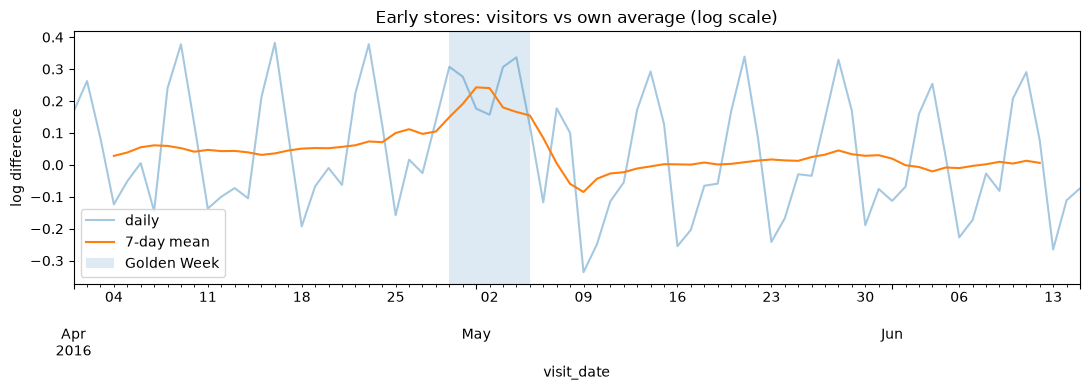

Golden Week vs early April: 1.15


In [9]:
first = visits.groupby("air_store_id")["visit_date"].min()
early = first[first <= "2016-04-01"].index
print("early stores:", len(early))

e = df[df["air_store_id"].isin(early) & df["visit_date"].between("2016-04-01", "2016-06-15")]
daily_rel = e.groupby("visit_date")["lv_rel"].mean()

fig, ax = plt.subplots(figsize=(11, 4))
daily_rel.plot(ax=ax, alpha=0.4, label="daily")
daily_rel.rolling(7, center=True).mean().plot(ax=ax, label="7-day mean")
ax.axvspan(pd.Timestamp("2016-04-29"), pd.Timestamp("2016-05-05"), alpha=0.15, label="Golden Week")
ax.set_title("Early stores: visitors vs own average (log scale)")
ax.set_ylabel("log difference")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "golden_week_2016.png", dpi=120)
plt.show()

gw = daily_rel["2016-04-29":"2016-05-08"].mean()
base = daily_rel["2016-04-01":"2016-04-21"].mean()
print("Golden Week vs early April:", round(np.exp(gw - base), 2))

In [10]:
h = cal[(cal["holiday_flg"] == 1) & (cal["calendar_date"] <= "2017-04-22")]
print(h[["calendar_date", "day_of_week"]].to_string())

print(cal[(cal["holiday_flg"] == 1) & (cal["calendar_date"] > "2017-04-22")])

    calendar_date day_of_week
0      2016-01-01      Friday
1      2016-01-02    Saturday
2      2016-01-03      Sunday
10     2016-01-11      Monday
41     2016-02-11    Thursday
79     2016-03-20      Sunday
80     2016-03-21      Monday
119    2016-04-29      Friday
123    2016-05-03     Tuesday
124    2016-05-04   Wednesday
125    2016-05-05    Thursday
199    2016-07-18      Monday
223    2016-08-11    Thursday
225    2016-08-13    Saturday
226    2016-08-14      Sunday
227    2016-08-15      Monday
262    2016-09-19      Monday
265    2016-09-22    Thursday
283    2016-10-10      Monday
307    2016-11-03    Thursday
327    2016-11-23   Wednesday
357    2016-12-23      Friday
363    2016-12-29    Thursday
364    2016-12-30      Friday
365    2016-12-31    Saturday
366    2017-01-01      Sunday
367    2017-01-02      Monday
368    2017-01-03     Tuesday
374    2017-01-09      Monday
407    2017-02-11    Saturday
444    2017-03-20      Monday
    calendar_date day_of_week  holiday_f

In [11]:
d = df["visit_date"]
newyear = ((d.dt.month == 12) & (d.dt.day >= 29)) | ((d.dt.month == 1) & (d.dt.day <= 3))
obon = (d.dt.month == 8) & d.dt.day.between(13, 15)
flag = df["holiday_flg"] == 1

df["hol_type"] = "normal"
df.loc[flag, "hol_type"] = "public"
df.loc[flag & newyear, "hol_type"] = "new_year"
df.loc[flag & obon, "hol_type"] = "obon"

# remove the plain weekday effect first, then compare the holiday types
df["lv_adj"] = df["lv_rel"] - df.groupby("day_of_week")["lv_rel"].transform("mean")
summary = df.groupby("hol_type").agg(rows=("lv_adj", "size"),
                                     dates=("visit_date", "nunique"),
                                     effect=("lv_adj", "mean"))
summary["effect"] = np.exp(summary["effect"]).round(2)
print(summary)

            rows  dates  effect
hol_type                       
new_year    2355      9    1.17
normal    239333    447    0.99
obon        1644      3    0.98
public      8776     19    1.17


In [12]:
per_store = visits.groupby("air_store_id")["visitors"].agg(mean="mean", n="count").reset_index()
s = per_store.merge(info, on="air_store_id", how="left")
s["prefecture"] = s["air_area_name"].str.split().str[0]

print("genres:", s["air_genre_name"].nunique(),
      "| areas:", s["air_area_name"].nunique(),
      "| prefectures:", s["prefecture"].nunique())
print(s.groupby("air_genre_name")["mean"].agg(stores="count", median_of_means="median")
        .sort_values("stores", ascending=False).round(1))
print(s["prefecture"].value_counts())
print(s["air_area_name"].value_counts().describe())

genres: 14 | areas: 103 | prefectures: 9
                              stores  median_of_means
air_genre_name                                       
Izakaya                          197             22.2
Cafe/Sweets                      181             20.0
Dining bar                       108             16.5
Italian/French                   102             20.7
Bar/Cocktail                      79             10.9
Japanese food                     63             16.8
Other                             27             18.8
Yakiniku/Korean food              23             20.9
Western food                      16             20.2
Okonomiyaki/Monja/Teppanyaki      14             23.7
Creative cuisine                  13             28.0
Asian                              2             39.4
International cuisine              2             23.9
Karaoke/Party                      2             31.4
prefecture
Tōkyō-to         444
Fukuoka-ken      127
Ōsaka-fu          74
Hyōgo-ken         57


In [13]:
dg = df.merge(info[["air_store_id", "air_genre_name"]], on="air_store_id", how="left")
top = dg["air_genre_name"].value_counts().head(4).index
sub = dg[dg["air_genre_name"].isin(top)]
print(np.exp(sub.pivot_table(index="day_of_week", columns="air_genre_name",
                             values="lv_rel", aggfunc="mean").reindex(order)).round(2).to_string())

air_genre_name  Cafe/Sweets  Dining bar  Italian/French  Izakaya
day_of_week                                                     
Monday                 0.87        0.79            0.81     0.79
Tuesday                0.86        0.83            0.86     0.86
Wednesday              0.92        0.91            0.94     0.96
Thursday               0.92        0.92            0.93     0.90
Friday                 0.94        1.19            1.17     1.30
Saturday               1.27        1.37            1.22     1.29
Sunday                 1.28        1.05            1.06     0.97


In [14]:
print(daily_rel["2016-04-29":"2016-05-08"].round(2))

visit_date
2016-04-29    0.31
2016-04-30    0.28
2016-05-01    0.18
2016-05-02    0.16
2016-05-03    0.31
2016-05-04    0.34
2016-05-05    0.12
2016-05-06   -0.12
2016-05-07    0.18
2016-05-08    0.10
Name: lv_rel, dtype: float64


In [15]:
chk = daily_rel["2016-04-01":"2016-06-15"].to_frame("lv_rel")
chk["day"] = chk.index.day_name()
print(chk[chk["day"].isin(["Monday", "Friday"])].round(2).to_string())

            lv_rel     day
visit_date                
2016-04-01    0.17  Friday
2016-04-04   -0.12  Monday
2016-04-08    0.24  Friday
2016-04-11   -0.14  Monday
2016-04-15    0.21  Friday
2016-04-18   -0.19  Monday
2016-04-22    0.22  Friday
2016-04-25   -0.16  Monday
2016-04-29    0.31  Friday
2016-05-02    0.16  Monday
2016-05-06   -0.12  Friday
2016-05-09   -0.34  Monday
2016-05-13    0.17  Friday
2016-05-16   -0.25  Monday
2016-05-20    0.17  Friday
2016-05-23   -0.24  Monday
2016-05-27    0.15  Friday
2016-05-30   -0.19  Monday
2016-06-03    0.16  Friday
2016-06-06   -0.23  Monday
2016-06-10    0.21  Friday
2016-06-13   -0.26  Monday


## Key findings (Day 5)
1. Weekday: relative to each store's own average, Saturday is the busiest day (ratio 1.27) and Monday the quietest (0.80). Store mix is not the reason: the average store size per weekday differs by only about 0.4 visitors (20.9 to 21.3).
2. Holidays: on Monday to Friday days flagged as holidays (the flag also covers New Year and Obon days), stores run 15% to 47% above a normal day of the same weekday (Monday +25% on 9 dates; Tuesday and Wednesday rest on only 2 dates each). Saturday holidays look lower (0.90) but rest on only 4 dates. After removing the weekday effect, public holidays and New Year both show 1.17 (19 and 9 dates), and Obon shows 0.98 (3 dates).
3. Golden Week: the 312 early stores ran 1.15 times their early-April level between 29 April and 8 May 2016 (a rough comparison). The unflagged Monday 2 May was still +0.16 above the stores' own average on the log scale (a typical Monday is below it), while the unflagged Friday 6 May was -0.12 (a typical Friday is above it). So holiday_flg alone does not describe the whole period, and the days around the holidays can move in either direction.
4. Store type: 14 genres; the two largest are Izakaya and Cafe/Sweets (378 stores together). Median store mean ranges from 10.9 (Bar/Cocktail) to 28.0 (Creative cuisine) among genres with at least 10 stores. Tokyo-to is the biggest prefecture with 444 of 829 stores.
5. Cardinality: 103 areas with a median of only 4 stores each, so raw area is too sparse and a coarser level (prefecture or city) is needed.